In [39]:
import pandas as pd
import datetime as dt
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pygments.styles.dracula import yellow

In [40]:
#تنظيف البيانات

f1 = pd.read_csv('data1.csv', sep=';')
print("\n", f1.head())
# تنظيف أسماء الأعمدة
f1.columns = f1.columns.str.strip()

# إعادة تسمية عمود التاريخ
f1 = f1.rename(columns={'§': 'Date'})

# حذف العمود الفارغ
f1 = f1.drop(columns=['Unnamed: 6'], errors='ignore')

# تعديل التاريخ
f1['Date'] = pd.to_datetime(f1['Date'], dayfirst=True, errors='coerce')
f1['Day'] = f1['Date'].dt.day
f1['Month'] = f1['Date'].dt.month
f1['Year'] = f1['Date'].dt.year

# حذف الصفوف الفارغة
f1 = f1.dropna()

# ترتيب الأعمدة
f1 = f1[['Date', 'Day', 'Month', 'Year', 'Branch', 'Category', 'product', 'Quantity', 'Price']]

# تنظيف القيم
# ١- حذف المسافات
f1['Branch'] = f1['Branch'].str.strip()
f1['Category'] = f1['Category'].str.strip()
f1['product'] = f1['product'].str.strip()

# ٢- استبدال القيم
f1['Branch'] = f1['Branch'].replace({
    'رياض': 'الرياض',
    'جدة': 'جده',
})

f1['Category'] = f1['Category'].replace({
    'اجهزة منزلية': 'أجهزة منزلية',
    'الكترونيات': 'إلكترونيات',
})

f1['product'] = f1['product'].replace({
    'حقيبه ظهر': 'حقيبة ظهر',
    'سماعات لاسلكيه': 'سماعات لاسلكية',
    'خلاط كهربائى': 'خلاط كهربائي',
    'شاشه كمبيوتر': 'شاشة كمبيوتر',
    'قميص رجالى': 'قميص رجالي',
    'مكواه بخار': 'مكواة بخار',
})

# للطباعة للتأكد من القيم في العمود المعدله قيمه
print(f1['Branch'].unique())
# عرض مرتب
f1.to_string()
print("\n", f1.head())


             § Branch        Category          product  Quantity  Price  \
0   3/01/2025    رياض   أجهزة منزلية   مكنسة كهربائية      35.0  380.0   
1  2025-03-04  الدمام     إلكترونيات   سماعات لاسلكيه      45.0  180.0   
2   5/06/2025  الدمام     إلكترونيات       ساعه ذكية        NaN  420.0   
3   5/06/2025     جده         ملابس         حقيبه ظهر      48.0  120.0   
4  2025-01-03  الدمام          ملابس       حذاء رياضي      33.0  210.0   

   Unnamed: 6  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  
<StringArray>
['الرياض', 'جده', 'الدمام']
Length: 3, dtype: str

         Date  Day  Month    Year  Branch      Category         product  \
0 2025-01-03  3.0    1.0  2025.0  الرياض  أجهزة منزلية  مكنسة كهربائية   
3 2025-06-05  5.0    6.0  2025.0     جده         ملابس       حقيبة ظهر   
5 2025-01-03  3.0    1.0  2025.0  الدمام  أجهزة منزلية  مكنسة كهربائية   
8 2025-02-02  2.0    2.0  2025.0     جده  أجهزة منزلية    خلاط كهربائي   
9 2025-06-05  5.0    

In [41]:
#تحليل البيانات

# إحصــــاد وصفـي
# مقاييس النزعة المركزية
f1['Quantity'] = f1['Quantity'].sort_index(ascending=True)
print("\nMax:", f1['Quantity'].max())
print("Min:", f1['Quantity'].min())
print("Mean:", f1['Quantity'].mean())
print("Median:", f1['Quantity'].median())
print("Mode:", f1['Quantity'].mode())


Max: 60.0
Min: 15.0
Mean: 37.42857142857143
Median: 39.0
Mode: 0    48.0
Name: Quantity, dtype: float64


In [42]:

# المركزية المئوية
print("\nQuantity10%:", f1['Quantity'].quantile(0.10, interpolation='nearest'))
Q1 = f1['Quantity'].quantile(0.25, interpolation='higher')
print("Q1:", Q1)
Q3 = f1['Quantity'].quantile(0.75, interpolation='higher')
print("Q3:", Q3)
# المدى الربيعي , IQR= Q3 - Q1
IQR = Q3 - Q1
print("IQR:", IQR)


Quantity10%: 20.0
Q1: 29.0
Q3: 46.0
IQR: 17.0


In [63]:

# مقاييس التشتت
print("\n  StdDev:", f1['Quantity'].std())
print("\n  Variance:", f1['Quantity'].var(ddof=0))  # تباين سكّاني
print("\n  Variance:", f1['Quantity'].var(ddof=1))  # تباين عيّني

# MAD (متوسط الانحراف المطلق)
mean_val = f1['Quantity'].mean()
mad = np.sum(np.abs(f1['Quantity'] - mean_val)) / len(f1['Quantity'])
print("MAD:", mad)

# Skewness (الميل)
skew_value = f1['Quantity'].skew()
print("Skewness:", skew_value)

# Kurtosis (التحدب)
kurtosis_value = f1['Quantity'].kurtosis()
print("Kurtosis:", kurtosis_value)

print(f1.to_csv('data2.csv', sep=';', index=False))



  StdDev: 11.480055168276268

  Variance: 129.10204081632654

  Variance: 131.79166666666666
MAD: 9.364431486880466
Skewness: -0.07051941131793364
Kurtosis: -0.7374965497598094
None


In [62]:
zـscore = (np.abs(f1['Quantity'] - f1['Quantity'].mean()) / f1['Quantity'].std())
print(zـscore)


0      0.211547
3      0.920852
5      0.559977
8      1.530605
9      0.223991
14     1.692376
16     0.298655
21     1.966143
24     0.746637
25     0.647085
32     0.049776
37     0.223991
46     0.124439
48     0.920852
50     1.617712
51     0.920852
53     0.746637
54     0.734193
55     0.659529
56     0.908408
61     1.082623
65     1.617712
73     1.953699
85     0.908408
88     0.223991
89     0.920852
93     0.659529
95     0.136883
96     0.136883
98     0.472870
101    1.169731
107    0.136883
108    0.037332
120    0.746637
122    0.298655
123    1.169731
128    1.704820
133    1.692376
134    0.920852
136    1.518161
137    0.398206
143    0.485314
144    1.518161
147    0.049776
150    1.182175
153    0.647085
154    1.518161
159    0.821300
164    0.136883
Name: Quantity, dtype: float64


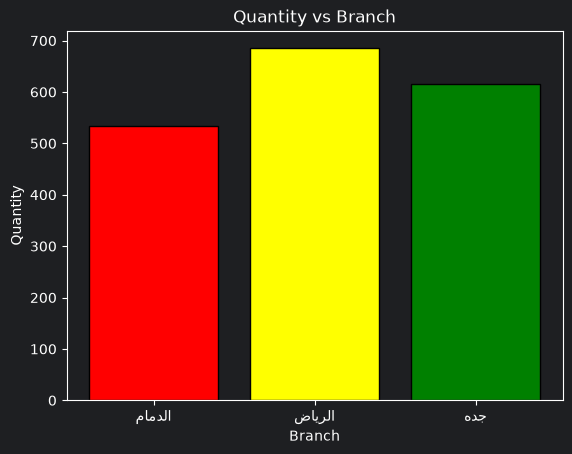

In [44]:
#تمثيل البيانات
"""
plt.bar(x, y) → رسم Bar Plot.
plt.xlabel() → اسم محور X.
plt.ylabel() → اسم محور Y.
width= → عرض العمود.
plt.title() → عنوان الرسم.
plt.show() → عرض الرسم.
"""
# تجميع الكميات حسب الفرع
# groupby('Branch') ← اسم العمود المراد التجميع حسبه.
# ['Quantity'] ← اختيار عمود Quantity بعد التجميع.

qqy = f1.groupby('Branch')['Quantity'].sum()
plt.bar(
    qqy.index, qqy.values,
    color=['red', 'yellow', 'green'],
    edgecolor='black',
    width=0.8
)

# العناوين تكون بأكواد منفصلة
plt.xticks(['الرياض', 'جده', 'الدمام'])
plt.xlabel('Branch')
plt.ylabel('Quantity')
plt.title('Quantity vs Branch')
plt.show()

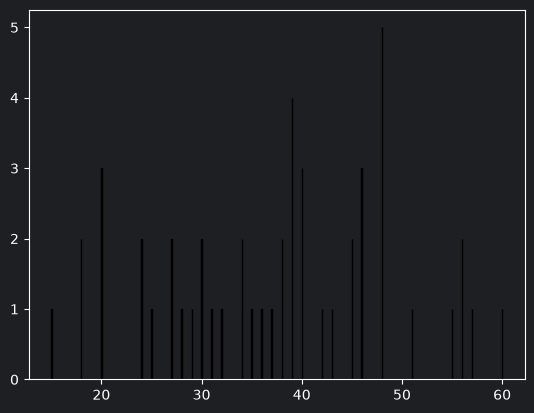

In [45]:

plt.hist(
    f1['Quantity'],
    bins=1000,
    color='blue',
    edgecolor='black',
    label='Quantity'
)

plt.show()

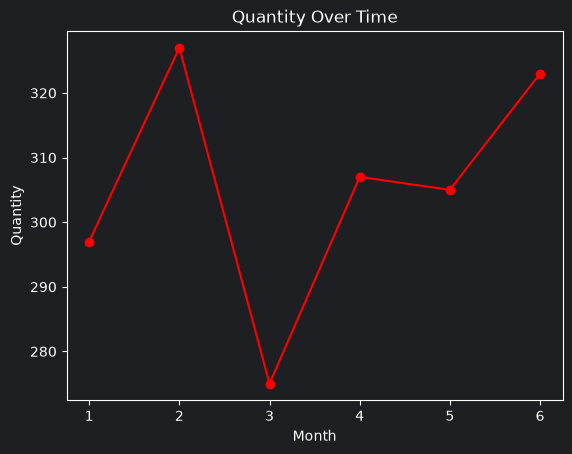

In [46]:

# تجميع الكميات حسب الفرع
# groupby('Date') ← اسم العمود المراد التجميع حسبه.
# ['Quantity'] ← اختيار عمود Quantity بعد التجميع.

da = f1.groupby('Month')['Quantity'].sum()

plt.plot(
    da.index, da.values,
    color='red',
    marker='o',
    linestyle='-',

)
plt.title('Quantity Over Time')
plt.ylabel('Quantity')
plt.xlabel('Month')
plt.show()

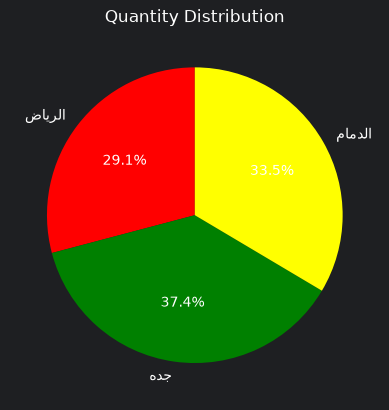

In [47]:

# تجميع الكميات حسب الفرع
# groupby('Branch') ← اسم العمود المراد التجميع حسبه.
# ['Quantity'] ← اختيار عمود Quantity بعد التجميع.

qty = f1.groupby('Branch')['Quantity'].sum()
plt.pie(
    qty,
    colors=['red', 'green', 'yellow'],
    labels=['الرياض', 'جده', 'الدمام'],
    startangle=90,
    autopct='%1.1f%%'
)
plt.title('Quantity Distribution')
plt.show()

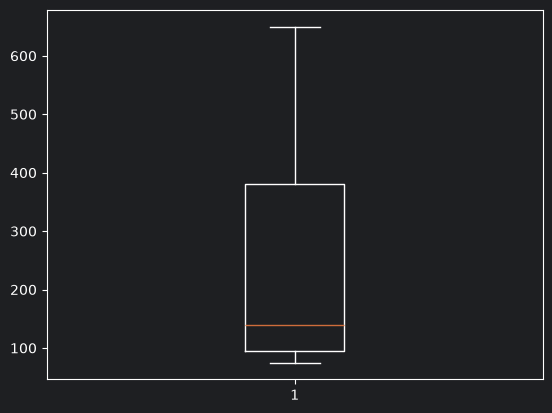

In [48]:

plt.boxplot(
    f1['Price'],
    whiskerprops=dict(linestyle='-'),
    orientation='vertical',
    widths=0.2,
    meanline=True,
)
plt.show()

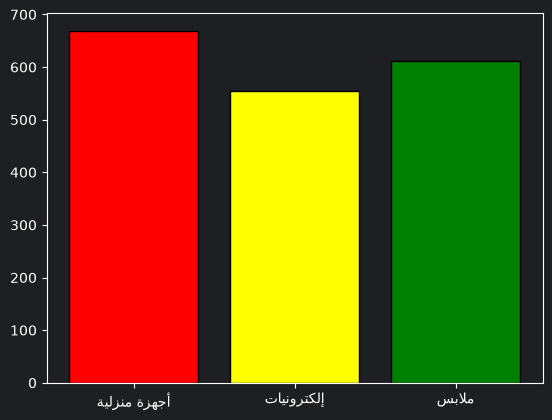

In [49]:

qql = f1.groupby('Category')['Quantity'].sum()
plt.bar(
    qql.index, qql.values,
    color=['red', 'yellow', 'green'],
    edgecolor='black',
    width=0.8
)

plt.show()

colors = {
    'الرياض': 'red',
    'جده': 'blue',
    'الدمام': 'green'
}

for branch in f1['Branch'].unique():
    data = f1[f1['Branch'] == branch];

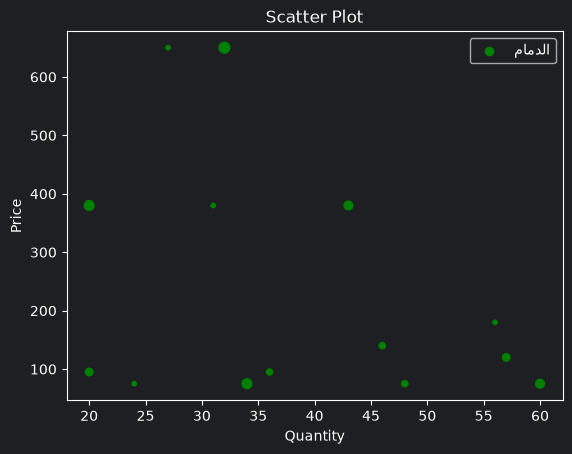

In [50]:

    # matplotlip (plt.scatter(.....)
    plt.scatter(
        data['Quantity'],  # المتغير الأول
        data['Price'],  # المتغير الثاني
        c=colors[branch],  # المتغير الثالث (اللون)
        s=data['Month'] / 0.1,  # المتغير الرابع (الحجم)
        label=branch
    )

    plt.xlabel('Quantity')
    plt.ylabel('Price')
    plt.title('Scatter Plot')
    plt.legend()
    plt.show()

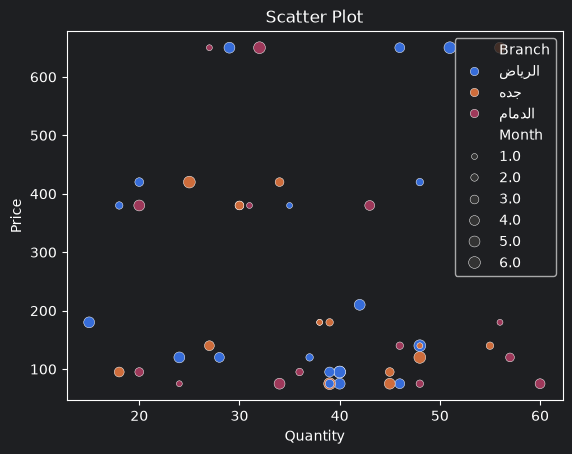

Category
أجهزة منزلية    19
ملابس           15
إلكترونيات      15
Name: count, dtype: int64


In [51]:


# seaborn sns.scatterplot(.....)
sns.scatterplot(
    data=f1,
    x='Quantity',
    y='Price',
    hue='Branch',  # اللون حسب الفرع
    size='Month'  # الحجم حسب الشهر

)

plt.title('Scatter Plot')
plt.show()

print(f1['Category'].value_counts())

In [52]:

from bokeh.plotting import figure, show

p = figure()
p.line([1, 2, 3], [4, 5, 6], line_width=2)
show(p)

In [53]:
# تجميع البيانات
data = f1.groupby(['Month', 'Branch'])['Quantity'].sum().unstack().fillna(0)

#multlines
x = [data.index.tolist()] * 3

y = [
data['الرياض'].tolist(),
data['جده'].tolist(),
data['الدمام'].tolist()
]

p = figure(
title="Quantity by Month",
x_axis_label="Month",
y_axis_label="Quantity"
)

p.multi_line(
xs=x,
ys=y,
color=["red", "blue", "green"],
line_width=2
)

show(p)


In [54]:

from bokeh.plotting import figure, show

# bokeh - line plot

# تجميع الكميات حسب الشهر والفرع
data = f1.groupby(['Month', 'Branch'])['Quantity'].sum().unstack().fillna(0)

#vline
# تحويل Month إلى عمود
data = data.reset_index()

p = figure(
    title="Quantity by Month",
    x_axis_label="Month",
    y_axis_label="Quantity"
)

p.vline_stack(
    ['الرياض', 'جده', 'الدمام'],
    x='Month',
    source=data,
    color=['red', 'blue', 'green'],
    legend_label=['الرياض', 'جده', 'الدمام']
)

show(p)



In [55]:

# تجميع الكميات حسب الشهر
qm = f1.groupby('Month')['Quantity'].sum()

p = figure(
    x_range=[str(x) for x in qm.index],
    title="Quantity by Month",
    x_axis_label="Month",
    y_axis_label="Quantity"
)

p.vbar(
    x=[str(x) for x in qm.index],
    top=qm.values,
    width=0.5,
    color=["red", "blue", "green", "orange", "purple", "brown"]
)
show(p)

In [56]:
qty = f1.groupby('Branch')['Quantity'].sum()
p = figure(x_range=f1['Branch'].unique().tolist())


p.vbar(
    x=qty.index,
    top=qty.values,
    width=0.5,
    color=["red", "green", "blue"]
)

show(p)

In [57]:

from bokeh.models import FullscreenTool

tool = FullscreenTool()

p.add_tools(tool)


from bokeh.models import ColumnDataSource

source = ColumnDataSource(f1)

p = figure(
    title="Quantity vs Price"
)

p.scatter(
    x='Quantity',
    y='Price',
    size=10,
    color='red',
    source=source
)
show(p)

In [58]:

#تجميع الكمية حسب الشهر:
qm = f1.groupby('Month')['Quantity'].sum().reset_index()

source = ColumnDataSource(qm)

p = figure(
    title="Quantity by Month",
    toolbar_location="below"
)

p.line(
    x='Month',
    y='Quantity',
    source=source,
    line_width=2
)

show(p)
